# Predicting student grades with linear regression

Dataset: `student-mat.csv` (UCI Student Performance). Target: `G3`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 552

## (a) Data exploration and pre-processing
### (a)i Import the data

In [3]:
# the file is semicolon separated
df_raw = pd.read_csv('../data/student-mat.csv', sep=';')
print(df_raw.shape)

(395, 33)


### (a)ii Select features, encode, combine `Dalc` and `Walc`

In [4]:
cols = ['age', 'studytime', 'schoolsup', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G3']
df = df_raw[cols].copy()

# binary encoding: no -> 0, yes -> 1
df['schoolsup'] = df['schoolsup'].map({'no': 0, 'yes': 1})

# combine weekday and weekend alcohol use by averaging, then drop the originals
df['alc'] = df[['Dalc', 'Walc']].mean(axis=1)
df = df.drop(columns=['Dalc', 'Walc'])

print('missing values per column:'); print(df.isna().sum()); print()
df.info(); print(); print(df.describe().round(2)); print()
df.head()

missing values per column:
age          0
studytime    0
schoolsup    0
goout        0
health       0
absences     0
G3           0
alc          0
dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        395 non-null    int64  
 1   studytime  395 non-null    int64  
 2   schoolsup  395 non-null    int64  
 3   goout      395 non-null    int64  
 4   health     395 non-null    int64  
 5   absences   395 non-null    int64  
 6   G3         395 non-null    int64  
 7   alc        395 non-null    float64
dtypes: float64(1), int64(7)
memory usage: 24.8 KB

          age  studytime  schoolsup   goout  health  absences      G3     alc
count  395.00     395.00     395.00  395.00  395.00    395.00  395.00  395.00
mean    16.70       2.04       0.13    3.11    3.55      5.71   10.42    1.89
std      1.28       0.84       0.34    1.11    1.

,age,studytime,schoolsup,goout,health,absences,G3,alc
0,18,2,1,4,3,6,6,1.0
1,17,2,0,3,3,4,6,1.0
2,15,2,1,2,3,10,10,2.5
3,15,3,0,2,5,2,15,1.0
4,16,2,0,2,5,4,10,1.5


### (a)iii Outliers per independent variable (IQR method)
A value is an outlier if it is below Q1 - 1.5 IQR or above Q3 + 1.5 IQR.

 variable   Q1   Q3  lower fence  upper fence  n outliers
      age 16.0 18.0        13.00        21.00           1
studytime  1.0  2.0        -0.50         3.50          27
schoolsup  0.0  0.0         0.00         0.00          51
    goout  2.0  4.0        -1.00         7.00           0
   health  3.0  5.0         0.00         8.00           0
 absences  0.0  8.0       -12.00        20.00          15
      alc  1.0  2.5        -1.25         4.75           9


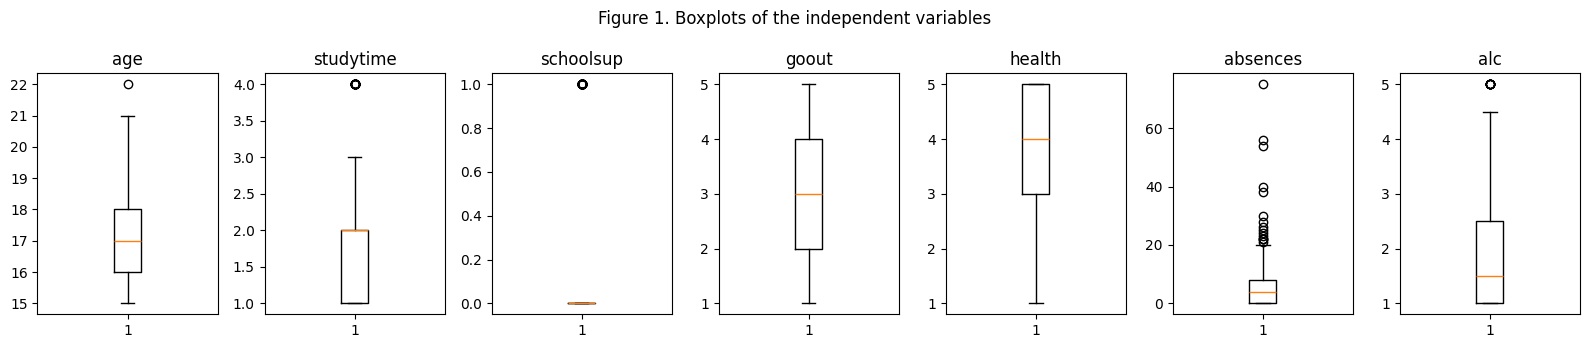

In [5]:
X_cols = [c for c in df.columns if c != 'G3']
rows = []
for c in X_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append((c, q1, q3, lo, hi, int(((df[c] < lo) | (df[c] > hi)).sum())))
outliers = pd.DataFrame(rows, columns=['variable', 'Q1', 'Q3', 'lower fence', 'upper fence', 'n outliers'])
print(outliers.to_string(index=False))

fig, axes = plt.subplots(1, len(X_cols), figsize=(16, 3.5))
for ax, c in zip(axes, X_cols):
    ax.boxplot(df[c]); ax.set_title(c)
plt.suptitle('Figure 1. Boxplots of the independent variables'); plt.tight_layout(); plt.show()

**Note.** `schoolsup` is 0/1, so its fences are 0 and 0 and every 1 is flagged. `studytime` is a 1 to 4 scale. These counts come from applying the IQR rule to discrete variables, not from data errors. The only continuous-like variables are `absences` and `alc`.

### (a)iv Standardize and run PCA
The independent variables are standardized (mean 0, standard deviation 1). PCA is run on these, and `G3` is used only for colouring. The standardized data is used for part (b).

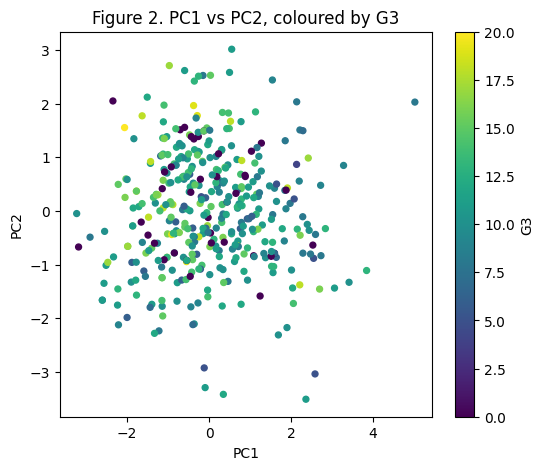

explained variance ratio: [0.237 0.171 0.152 0.14  0.127 0.095 0.078]
             PC1    PC2
age        0.382  0.589
studytime -0.330  0.386
schoolsup -0.248 -0.464
goout      0.494 -0.140
health     0.081 -0.401
absences   0.280  0.183
alc        0.596 -0.274
PC1 largest absolute loadings: alc (+0.596), goout (+0.494), age (+0.382)
PC2 largest absolute loadings: age (+0.589), schoolsup (-0.464), health (-0.401)


In [6]:
scaler = StandardScaler()
Xs = pd.DataFrame(scaler.fit_transform(df[X_cols]), columns=X_cols)
y = df['G3'].reset_index(drop=True)

pca = PCA(random_state=SEED)
Z = pca.fit_transform(Xs)

plt.figure(figsize=(6, 5))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=y, cmap='viridis', s=18)
plt.colorbar(sc, label='G3')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Figure 2. PC1 vs PC2, coloured by G3'); plt.show()

print('explained variance ratio:', pca.explained_variance_ratio_.round(3))
loadings = pd.DataFrame(pca.components_[:2].T, index=X_cols, columns=['PC1', 'PC2'])
print(loadings.round(3))
for pc in ['PC1', 'PC2']:
    top = loadings[pc].abs().sort_values(ascending=False).head(3)
    print(pc, 'largest absolute loadings:', ', '.join(f'{k} ({loadings.loc[k, pc]:+.3f})' for k in top.index))

**Loadings.** PC1 is driven mainly by alc (+0.596), goout (+0.494) and age (+0.382); studytime (-0.330) and schoolsup (-0.248) pull the other way. PC2 is driven mainly by age (+0.589), schoolsup (-0.464) and health (-0.401), with studytime (+0.386) next. PC1 and PC2 together explain about 41% of the variance (23.7% and 17.1%), and the other five components each explain 8% to 15%, so no small set of components captures the data. The scatterplot shows no visible colour pattern in G3 along PC1 or PC2. PC1 can be read as a going-out and alcohol axis (alc, goout and age high, studytime low). PC2 separates students with high age and studytime from students with high schoolsup and health. PCA is run on the 7 independent variables only, and G3 is not part of it.

## (b) Linear regression
### (b)i Train/test split (80:20, seed 552)
The question standardizes in (a)iv and keeps that data, so the scaler was fit on all 395 rows before this split. Test rows therefore influenced the means and standard deviations. The effect is small here but it is a leak.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(Xs, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

(316, 7) (79, 7)


### (b)ii Build the three models (alpha = 0.1)

In [8]:
models = {
    'A. Linear': LinearRegression(),
    'B. Ridge': Ridge(alpha=0.1),
    'C. Lasso': Lasso(alpha=0.1),
}
for m in models.values():
    m.fit(X_train, y_train)

### (b)iii Test-set performance

              MAE    RMSE      R2
model                            
A. Linear  3.4180  4.7558  0.0282
B. Ridge   3.4181  4.7559  0.0282
C. Lasso   3.4471  4.7938  0.0126
best MAE : A. Linear
best RMSE: A. Linear
best R2  : A. Linear


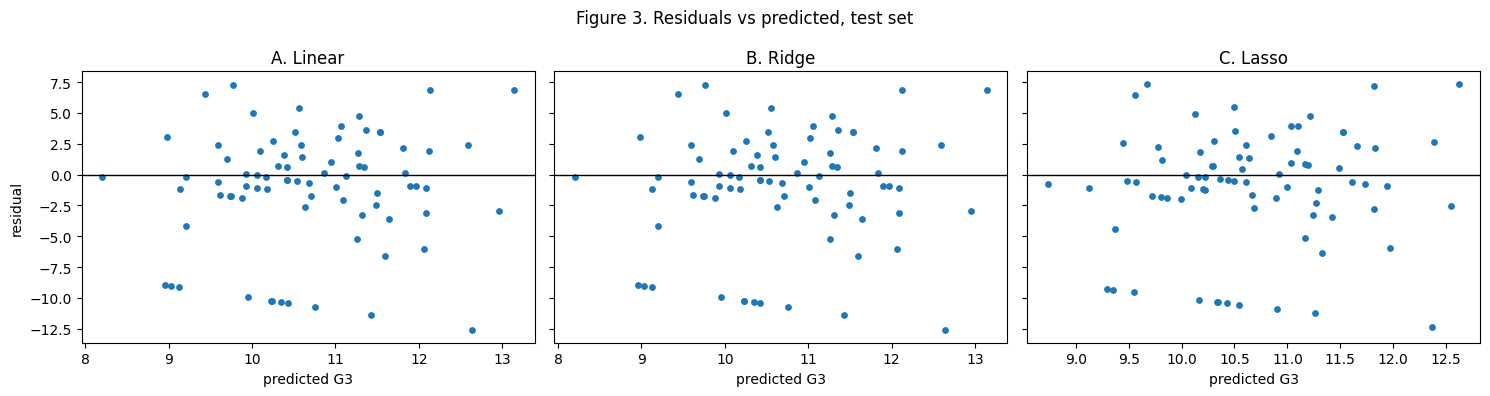

In [9]:
res = []
for name, m in models.items():
    p = m.predict(X_test)
    res.append((name, mean_absolute_error(y_test, p),
                np.sqrt(mean_squared_error(y_test, p)), r2_score(y_test, p)))
metrics = pd.DataFrame(res, columns=['model', 'MAE', 'RMSE', 'R2']).set_index('model')
print(metrics.round(4))
print('best MAE :', metrics['MAE'].idxmin())
print('best RMSE:', metrics['RMSE'].idxmin())
print('best R2  :', metrics['R2'].idxmax())

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    p = m.predict(X_test)
    ax.scatter(p, y_test - p, s=15); ax.axhline(0, color='k', lw=1)
    ax.set_title(name); ax.set_xlabel('predicted G3')
axes[0].set_ylabel('residual')
plt.suptitle('Figure 3. Residuals vs predicted, test set'); plt.tight_layout(); plt.show()

**Reading the table.** Model A is best on MAE, RMSE and R2, but A and B differ only in the fourth decimal (MAE 3.4180 vs 3.4181), so they are effectively tied. Model C is slightly worse. All three differences come from one split with 79 test rows, so they are too small to rank the models with confidence.

In [10]:
# residual diagnostic: students with G3 = 0
res_df = pd.DataFrame({'G3': y_test.values, 'resid_A': (y_test - models['A. Linear'].predict(X_test)).values})
zero = res_df['G3'] == 0
print('G3 = 0 in full data :', int((y == 0).sum()), 'of', len(y))
print('G3 = 0 in test set  :', int(zero.sum()), 'of', len(res_df))
print('mean residual, G3 = 0 :', round(res_df.loc[zero, 'resid_A'].mean(), 2))
print('mean residual, G3 > 0 :', round(res_df.loc[~zero, 'resid_A'].mean(), 2))
print('residuals below -8 that are G3 = 0:', int(((res_df['resid_A'] < -8) & zero).sum()), 'of', int((res_df['resid_A'] < -8).sum()))

G3 = 0 in full data : 38 of 395
G3 = 0 in test set  : 11 of 79
mean residual, G3 = 0 : -10.28
mean residual, G3 > 0 : 0.42
residuals below -8 that are G3 = 0: 11 of 11


**Residual analysis.** In Figure 3 about ten points sit far below zero (residuals from -9 to -12.5) in all three models. The check above shows these are exactly the students with G3 = 0: 11 of the 79 test rows, with a mean residual of -10.28 against +0.42 for everyone else, and all 11 residuals below -8 are G3 = 0. A zero is probably a missed or voided exam, which none of these seven predictors can explain, so the model overpredicts them by about 10 points. This is the main reason R2 is so low. Apart from that group, the residuals are spread around zero with no clear trend against the predicted value.

### (b)iv Interpreting R-squared
R2 is the share of the variance in G3 that the model explains on the test set. All three models are close to zero (A 0.0282, B 0.0282, C 0.0126), so these seven features explain only about 1% to 3% of the variation in final grade. Predictions are only slightly better than always predicting the mean grade. The RMSE of about 4.76 is close to the standard deviation of G3 (4.58 on the full data), which says the same thing.

### (b)v Coefficients

In [11]:
coef = pd.DataFrame({n: m.coef_ for n, m in models.items()}, index=X_cols)
coef.loc['intercept'] = [m.intercept_ for m in models.values()]
print(coef.round(4))

           A. Linear  B. Ridge  C. Lasso
age          -0.7811   -0.7807   -0.6304
studytime     0.4448    0.4447    0.3491
schoolsup    -0.6825   -0.6822   -0.5475
goout        -0.5825   -0.5823   -0.4856
health       -0.2433   -0.2432   -0.1416
absences      0.1928    0.1927    0.0720
alc           0.0371    0.0369   -0.0000
intercept    10.6294   10.6294   10.6251


### (b)vi Relationship of each variable with G3
Signs of the coefficients in model A, with all variables standardized, so each is the change in G3 for a one standard deviation increase: age -0.78 (older students score lower), studytime +0.44 (more study time, higher grade), schoolsup -0.68 (students receiving extra school support score lower; a possible reason is that support goes to weaker students, but this data cannot show that), goout -0.58 (going out more goes with lower grades), health -0.24 (better self-reported health goes with slightly lower grades, which is counterintuitive and small), absences +0.19 (the sign is positive, but the raw correlation of absences with G3 is only 0.034, and 0.084 with the 15 outliers removed, so there is essentially no relationship and the sign should not be interpreted), alc +0.04 (near zero, and its raw correlation with G3 is -0.058, so treat it as no relationship). Raw correlations with G3 for reference: age -0.162, studytime +0.098, goout -0.133, health -0.061, schoolsup -0.083. These are associations in this sample. No significance tests were run, so the small coefficients should not be over-read.

### (b)vii Regularization methods and what the dataset shows
Ridge adds an L2 penalty, which shrinks all coefficients toward zero smoothly and never sets one exactly to zero. Lasso adds an L1 penalty, which can set coefficients exactly to zero; at alpha = 0.1 it removed alc (coefficient 0.0000) and shrank the others more than ridge did (age -0.63 vs -0.78). Ridge at alpha = 0.1 is almost identical to ordinary least squares (same metrics to three decimals), so the features show no serious collinearity or overfitting that regularization needs to fix: with 316 training rows and 7 features, plain linear regression is not overfitting. Lasso did slightly worse on every metric (R2 0.0126 vs 0.0282), but the gap is small and comes from one split with 79 test rows. The overall conclusion is that these seven features are weak predictors of G3, not that the model is poorly regularized. alc is the weakest feature, which agrees with its near-zero coefficient and its removal by lasso.

### (b)viii Effect of increasing alpha

In [12]:
rows = []
for kind, cls in [('Ridge', Ridge), ('Lasso', Lasso)]:
    for a in [0.01, 0.1, 1, 10, 100]:
        m = cls(alpha=a).fit(X_train, y_train); p = m.predict(X_test)
        rows.append((kind, a, mean_absolute_error(y_test, p), np.sqrt(mean_squared_error(y_test, p)),
                     r2_score(y_test, p), int((m.coef_ != 0).sum())))
sweep = pd.DataFrame(rows, columns=['model', 'alpha', 'MAE', 'RMSE', 'R2', 'nonzero coefs'])
print(sweep.round(4).to_string(index=False))

model  alpha    MAE   RMSE      R2  nonzero coefs
Ridge   0.01 3.4180 4.7558  0.0282              7
Ridge   0.10 3.4181 4.7559  0.0282              7
Ridge   1.00 3.4185 4.7563  0.0280              7
Ridge  10.00 3.4231 4.7604  0.0263              7
Ridge 100.00 3.4590 4.7934  0.0128              7
Lasso   0.01 3.4202 4.7605  0.0262              7
Lasso   0.10 3.4471 4.7938  0.0126              6
Lasso   1.00 3.5987 4.9255 -0.0424              0
Lasso  10.00 3.5987 4.9255 -0.0424              0
Lasso 100.00 3.5987 4.9255 -0.0424              0


Larger alpha means stronger shrinkage, so the coefficients move toward zero and the predictions toward the training mean of G3. On the test set the metrics get worse as alpha grows. Ridge degrades slowly (R2 0.0282 at alpha 0.01, 0.0263 at 10, 0.0128 at 100). Lasso degrades faster: at alpha = 1 and above every coefficient is zero, the model predicts the constant intercept, and R2 is -0.0424 (negative because the training mean is a worse guess than the test mean). Very small alpha behaves like ordinary least squares. In this dataset regularization does not help at any alpha tried, because there is little overfitting to remove.

### (b)ix Feature engineering suggestions
1. Transform absences (log(1 + absences) or capping) because it is heavily right-skewed with 15 outliers and a maximum of 75. 
2. Treat ordinal variables with few levels (studytime, goout, health) as categories with one-hot encoding, in case the effect is not linear. 
3. Add interaction terms such as studytime x schoolsup and goout x alc, and polynomial terms for age. 
4. Use more of the columns in the file that were not selected here (for example failures, higher, Medu, Fedu) and check which improve cross-validated R2. 
5. Look at the G3 = 0 rows separately, since a zero is likely a different process (a missing exam) than a low score. 
6. Use cross-validation to choose alpha rather than fixing 0.1, and compare tree-based models if non-linear structure is suspected. 
7. Use the PCA components as inputs only if collinearity becomes a problem, which it does not appear to be here.